# **Atividade Prática A1 - 17/09/2026**

## *Seleção sistemática de modelos*
**Por [Ariel Ladislau Reises](https://www.arielreises.com.br) - 17/09/2026**

### **Objetivo:**

Construir um processo completo de classificação utilizando os conceitos estudados em aula: separação adequada dos dados, Pipeline, validação cruzada, GridSearchCV, seleção de hiperparâmetros e avaliação final

In [ ]:
# Importação de bibliotecas

import pandas as pd
import numpy as np

### **Base de Dados**

Utilize a base de dados **Breast Cancer Wisconsin**, disponibilizada diretamente pelo Scikit-Learn por meio da função `load_breast_cancer()`.

* 569 registros.
* 30 características numéricas.
* 2 classes de classificação.
* A base deve ser carregada diretamente pelo Scikit-Learn.


In [ ]:
# Importação de módulos para criação do Dataset

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

In [ ]:
# Criação do Dataset

dados = load_breast_cancer()

X = dados.data
y = dados.target

print(f"Quantidade de registros: {X.shape[0]}")
print(f"Quantidade de características: {X.shape[1]}")
print(f"Classes: {dados.target_names}")

### **Tarefa:**

Desenvolva um programa em Python utilizando `Scikit-Learn` para comparar quatro modelos de classificação estudados na disciplina:

* Árvore de Decisão - `DecisionTreeClassifier`
* Random Forest - `RandomForestClassifier`
* AdaBoost - `AdaBoostClassifier`
* Rede Neural - `MLPClassifier`


## **Etapas Obrigatórias**

### **01. Separação dos dados**

Separe a base em conjunto de treinamento e conjunto de teste, utilizando:
* 80% dos dados para treinamento.
* 20% dos dados para teste.
* O conjunto de teste deve permanecer separado durante todo o processo de seleção dos modelos

In [ ]:
# Divisão de Treino e Teste

X_treino, X_teste, y_treino, y_teste = train_test_split(X,
                                                        y,
                                                        test_size=0.2,
                                                        random_state=42,
                                                        stratify=y)

print(f"Registros para treinamento: {X_treino.shape[0]}")
print(f"Registros para teste: {X_teste.shape[0]}")

### **02. Construção dos Pipelines**

**Crie um Pipeline para cada um dos quatro modelos**.

> *Para a MLP, inclua uma etapa de padronização utilizando `StandardScaler` antes do modelo. Para os modelos baseados em árvores, não é necessário utilizar padronização.*



In [ ]:
# Importações de módulos para criação dos Pipelines

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier

In [ ]:
# Criação dos Pipelines dos modelos

modelos = {
    "01. Árvore de Decisão": Pipeline([
        ('clf', DecisionTreeClassifier(random_state=42))
    ]),

    "02. Random Forest": Pipeline([
        ('clf', RandomForestClassifier(random_state=42))
    ]),

    "03. AdaBoost": Pipeline([
        ('clf', AdaBoostClassifier(random_state=42))
    ]),

    "04. MLP": Pipeline([
        ('scaler', StandardScaler()), # Padronização utilizando o StandardScaler antes do Modelo
        ('clf', MLPClassifier(max_iter=1000,
                              random_state=42))
    ])
}

### **03. Definição dos Hiperparâmetros**
Utilize os seguintes valores como possibilidades de busca. Os nomes devem ser utilizados corretamente no contexto do Pipeline.

| Modelo | Hiperparâmetro | Valores a testar |
|---|---|---|
| Árvore de Decisão | `max_depth` | `[3, 5, 10]` |
| Random Forest | `n_estimators` | `[50, 100]` |
| Random Forest | `max_depth` | `[5, 10]` |
| AdaBoost | `n_estimators` | `[50, 100]` |
| AdaBoost | `learning_rate` | `[0.5, 1.0]` |
| MLP | `hidden_layer_sizes` | `[(10,), (20,)]` |
| MLP | `alpha` | `[0.0001, 0.001]` |

In [ ]:
# Parametrização do GridSearch

grades_parametros = {
    "01. Árvore de Decisão": {
        'clf__max_depth': [3, 5, 10]
    },

    "02. Random Forest": {
        'clf__n_estimators': [50, 100],
        'clf__max_depth': [5, 10]
    },

    "03. AdaBoost": {
        'clf__n_estimators': [50, 100],
        'clf__learning_rate': [0.5, 1.0]
    },

    "04. MLP": {
        'clf__hidden_layer_sizes': [(10,), (20,)],
        'clf__alpha': [0.0001, 0.001]
    }
}

### **04. GridSearchCV**

Utilize `GridSearchCV` para realizar a busca sistemática pelas configurações dos modelos.
* Utilize validação cruzada com 5 folds `(cv=5)`.
* Utilize accuracy como métrica de avaliação `(scoring='accuracy')`.
* A busca deve ser realizada utilizando os dados de treinamento.
* O conjunto de teste não deve participar da busca pelos hiperparâmetros.

In [ ]:
# Implementação do GridSearch

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

In [ ]:
# Criação e treinamento dos Grids

resultados = []

for nome, esteira_modelo in modelos.items():
    print(f"Iniciando treinamento do modelo: \033[1m{nome}\033[0m")

    otimizador = GridSearchCV(estimator=esteira_modelo,
                              param_grid=grades_parametros[nome],
                              cv=5, # 5 folds
                              scoring='accuracy', # Métrica de avaliação
                              n_jobs=-1)

    # Fit realizado somente com os dados de treinamento
    otimizador.fit(X_treino, y_treino)

    # Melhor estimador encontrado pelo GridSearch
    melhor_modelo = otimizador.best_estimator_

    # Predição utilizando o conjunto de teste
    y_pred = melhor_modelo.predict(X_teste)

    # Cálculo da acurácia no conjunto de teste
    acuracia_teste = accuracy_score(y_teste, y_pred)

    # Append dos Resultados
    resultados.append({
        'Modelo': nome,
        'Melhor configuração': otimizador.best_params_,
        'Best Score (CV)': otimizador.best_score_,
        'Acurácia no teste': acuracia_teste
    })

    print(f"Melhores parâmetros: {otimizador.best_params_}")
    print(f"Melhor Accuracy na validação: {otimizador.best_score_:.4f}")
    print(f"Acurácia no teste: {acuracia_teste:.4f}\n")

# Mensagem ao finalizar todos os modelos
print("\033[1;32mModelos treinados com sucesso!\033[0m")

### **05. Resultados que devem ser obtidos:**

Para cada modelo, obtenha e registre:
* `best_params_` -  melhor combinação de hiperparâmetros encontrada.
* `best_score_` - melhor score médio obtido na validação cruzada.
* Acurácia no conjunto de teste utilizando o melhor estimador.

In [ ]:
# Criação da Tabela Final

tabela_resultados = pd.DataFrame(resultados)

# Formatação das métricas para facilitar a leitura
tabela_resultados['Best Score (CV)'] = tabela_resultados['Best Score (CV)'].round(4)
tabela_resultados['Acurácia no teste'] = tabela_resultados['Acurácia no teste'].round(4)

display(tabela_resultados)


### **Tabela Final - Resultados dos Modelos**

Apresente os resultados em uma tabela semelhante à seguinte:

| Modelo | Melhor configuração | Best Score (CV) | Acurácia no teste |
|---|---|---:|---:|
| Árvore de Decisão | — | — | — |
| Random Forest | — | — | — |
| AdaBoost | — | — | — |
| MLP | — | — | — |

### **Tabela Final - Resultados dos Modelos:**
*(Já bonitinha em Markdown)*

| Modelo | Melhor configuração | Best Score (CV) | Acurácia no teste |
|---|---|---:|---:|
| Árvore de Decisão | `{'clf__max_depth': 5}` | 0.9319 | 0.9211 |
| Random Forest | `{'clf__max_depth': 10, 'clf__n_estimators': 100}` | 0.9538 | 0.9561 |
| AdaBoost | `{'clf__learning_rate': 0.5, 'clf__n_estimators': ...}` | 0.9780 | 0.9561 |
| MLP | `{'clf__alpha': 0.0001, 'clf__hidden_layer_size': ...}` | 0.9824 | 0.9649 |

### **O que deve ser entregue:**

* Código-fonte completo desenvolvido pelo aluno.
* Tabela final contendo os resultados dos quatro modelos:
  1.   Árvore de Decisão
  2.   Random Forest
  3.   AdaBoost
  4.   MLP
* O código deve executar sem erros e produzir os resultados apresentados na tabela.

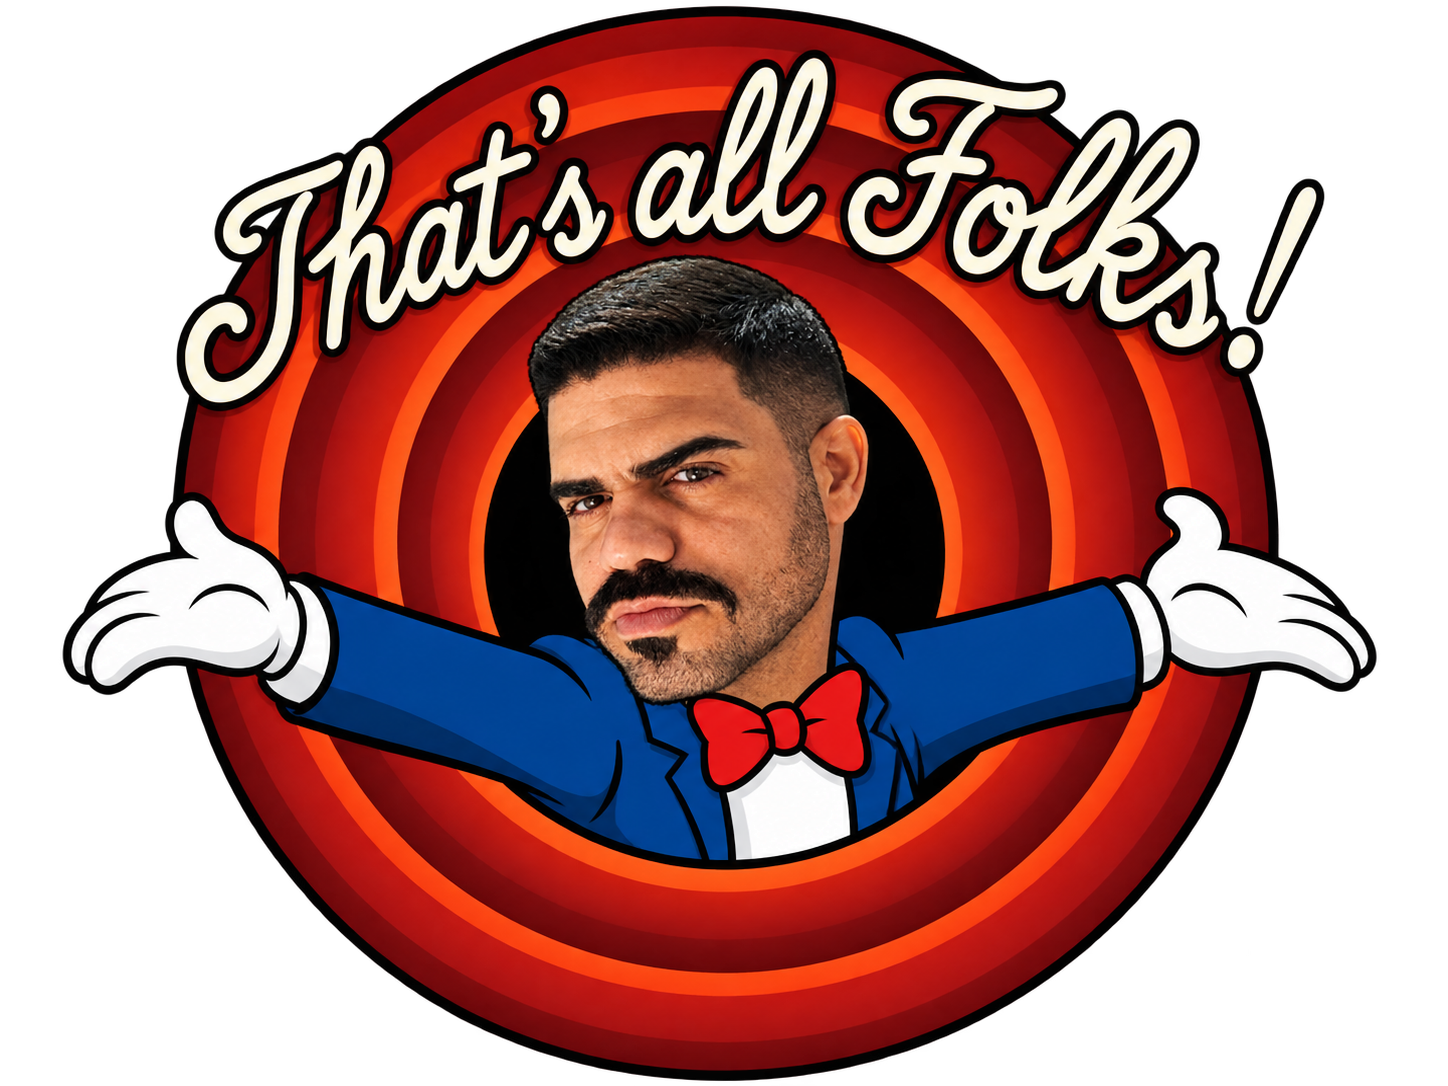

> *O único uso de Inteligência Artificial nesse jupyter notebook foi na criação da imagem acima.*